# Graph Neural Network (GNN) using GCN (Graph Convolution Layer)

A GNN is a Neural Network designed to learn from this graph format data.

How a GNN works -->

1. Every NODE starts with some features.

2. Each NODE collects (AGGREGATES) information from its neighbours.

3. It combines that with its own information to update itself.

4. Repeat this for a few 'LAYERS'.

How GCN (Graph Convolutiona Network) works -->

New_feature (node) = Activation (avg of [feature of Neighbours + Itself], Transformed by Weights)

MORE CONCRETELY, each GCN layer:

1. Gathers the feature vectors of each node's neighbours (and itself).

2. AVERAGE them and MULTIPLIES by a learnable weight matrix (like any neural network layer).

3. Applies a non-lineratiy OR activation function (like ReLU).

# CORA Dataset (Research Paper) based on 7 topics -->

1. Neural Network, 2. Rule Learning, 3. Reinforcement Learning, 4. Probabilities Methods, 5. Theory, 6. Genetic Algorithms, 7. Case-Based

In Dataset, nodes --> Research Paper (2708); edges --> Citation (10,556); features --> Information about each R.P (1433 per Paper); classes/levels --> Topics (7)

# What will we do in this PROJECT?

We will select a Node (Research Paper) and by analyzing it's neighbouring Nodes, we will decide this Node or Research Paper based on which Research Topics.

# Coding Start from Here

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch.nn.functional as F
import torch

In [2]:
# %pip install torch-geometric
from torch_geometric.datasets import Planetoid

In [3]:
dataset = Planetoid(root='data/Planetoid', name='Cora')

Processing...
Done!


In [14]:
data = dataset[0]  

print(f'Number of papers/nodes in the Cora dataset: {data.num_nodes}')
print(f'Number of citation/edges in the Cora dataset: {data.num_edges}')
print(f'Number of features(in every paper) in the Cora dataset: {data.num_features}')
print(f'Number of classes in the Cora dataset: {dataset.num_classes}')

print('----------------------------------------')

print(f'Number of training papers/nodes: {data.train_mask.sum()}')
print(f'Number of validation papers/nodes: {data.val_mask.sum()}')
print(f'Number of testing papers/nodes: {data.test_mask.sum()}')

Number of papers/nodes in the Cora dataset: 2708
Number of citation/edges in the Cora dataset: 10556
Number of features(in every paper) in the Cora dataset: 1433
Number of classes in the Cora dataset: 7
----------------------------------------
Number of training papers/nodes: 140
Number of validation papers/nodes: 500
Number of testing papers/nodes: 1000


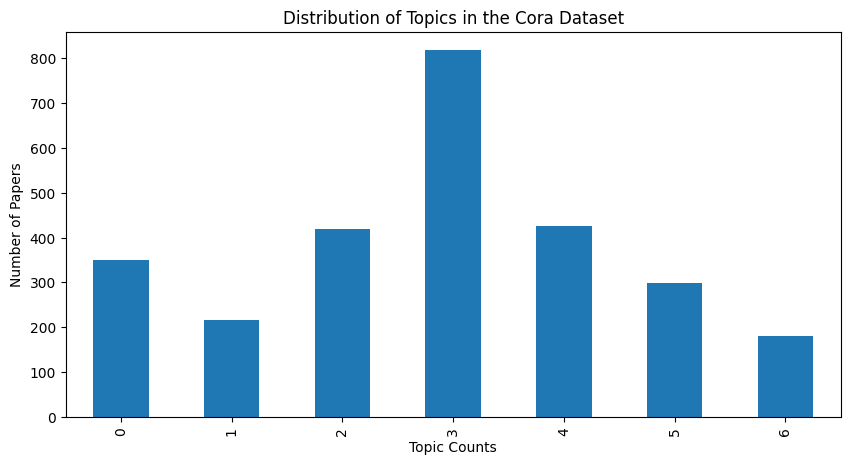

In [24]:
# Covert Tensor to Numpy Array
topic_counts =pd.Series(data.y.numpy()).value_counts().sort_index()
topic_counts.plot(x=topic_counts.index, y=topic_counts.values, kind='bar', figsize=(10, 5))
xlabel = 'Topic Counts'
plt.xlabel(xlabel)
plt.ylabel('Number of Papers')
plt.title('Distribution of Topics in the Cora Dataset')
plt.show()

# Baseline: TF-IDF-Style features plus Random Forest

In [33]:
X_binary = data.x.numpy()
y = data.y.numpy()

In [38]:
# Tf-idf Transformation
from sklearn.feature_extraction.text import TfidfTransformer


tfidf = TfidfTransformer()
X_tfidf = tfidf.fit_transform(X_binary).toarray()
X_baseline = X_tfidf    # Features


train_idx = data.train_mask.numpy() # Training Papers/Nodes
val_idx = data.val_mask.numpy() # Validation Papers/Nodes
test_idx = data.test_mask.numpy()   # Testing Papers/Nodes


X_train = X_baseline[train_idx] # We are taking the features from the Training Papers
y_train = y[train_idx]          # We are taking the labels/indices from the Training Papers

X_val = X_baseline[val_idx]     # We are taking the features from the Validation Papers
y_val = y[val_idx]              # We are taking the labels/indices from the Validation Papers

X_test = X_baseline[test_idx]   # We are taking the features from the Testing Papers
y_test = y[test_idx]            # We are taking the labels/indices from the Testing Papers

In [40]:
# Trained Random Forest Classifier --> It can handle class imbalance by adjusting weights
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=42, class_weight='balanced', n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

# Evaluation

In [43]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
print('Accuracy:', accuracy_score(y_test, rf_pred))
print('F1 Score:', f1_score(y_test, rf_pred, average='weighted'))

Accuracy: 0.58
F1 Score: 0.5840464521048923
